Setup

In [1]:
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.append(os.getcwd())

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error
from src.trends import poly_model, loo_mse, share_table
from src.data_loader import load_year

os.makedirs("reports", exist_ok=True)
rng = np.random.default_rng(42)

Make synthetic data and Fit three degrees

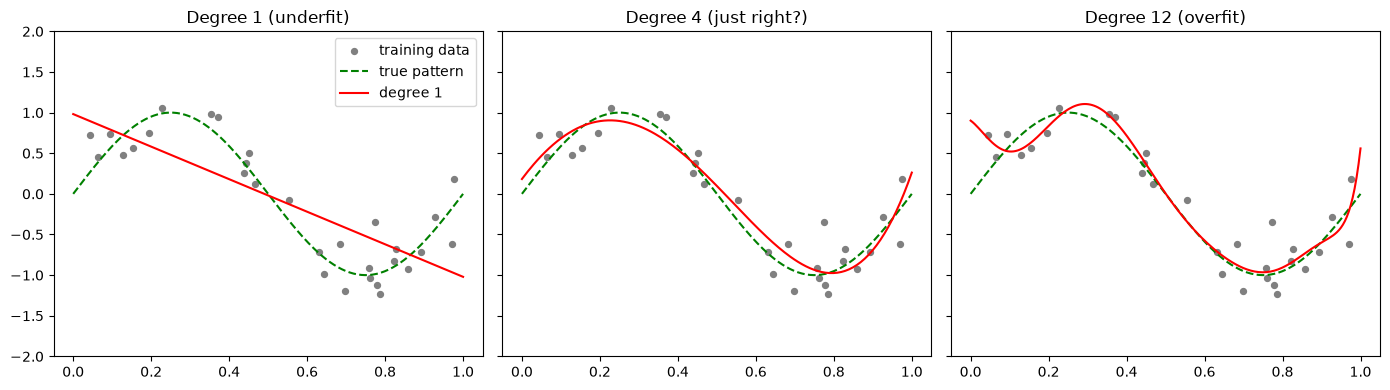

In [2]:
def true_fn(x):
    return np.sin(2 * np.pi * x)

n_train, noise_sd = 30, 0.3
x_train = rng.uniform(0, 1, n_train)
y_train = true_fn(x_train) + rng.normal(0, noise_sd, n_train)
x_test = rng.uniform(0, 1, 300)
y_test = true_fn(x_test) + rng.normal(0, noise_sd, 300)

grid = np.linspace(0, 1, 200).reshape(-1, 1)
fig, ax = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for a, d, name in zip(ax, [1, 4, 12], ["underfit", "just right?", "overfit"]):
    m = poly_model(d).fit(x_train.reshape(-1, 1), y_train)
    a.scatter(x_train, y_train, s=18, color="gray", label="training data")
    a.plot(grid, true_fn(grid.ravel()), "g--", label="true pattern")
    a.plot(grid, m.predict(grid), "r", label=f"degree {d}")
    a.set_title(f"Degree {d} ({name})")
    a.set_ylim(-2, 2)
ax[0].legend()
plt.tight_layout()
plt.savefig("reports/bias_variance_fits.png", dpi=150)
plt.show()

Training error vs Test error (the U-curve)

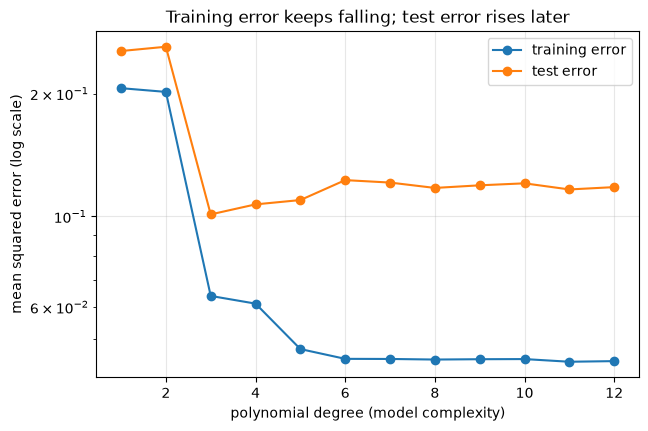

Degree with the lowest test error in YOUR run: 3


In [3]:
degrees = list(range(1, 13))
train_err, test_err = [], []
for d in degrees:
    m = poly_model(d).fit(x_train.reshape(-1, 1), y_train)
    train_err.append(mean_squared_error(y_train, m.predict(x_train.reshape(-1, 1))))
    test_err.append(mean_squared_error(y_test, m.predict(x_test.reshape(-1, 1))))

plt.figure(figsize=(7, 4.5))
plt.plot(degrees, train_err, "o-", label="training error")
plt.plot(degrees, test_err, "o-", label="test error")
plt.yscale("log")
plt.xlabel("polynomial degree (model complexity)")
plt.ylabel("mean squared error (log scale)")
plt.title("Training error keeps falling; test error rises later")
plt.legend(); plt.grid(alpha=0.3)
plt.savefig("reports/train_vs_test_error.png", dpi=150)
plt.show()

best = degrees[int(np.argmin(test_err))]
print("Degree with the lowest test error in YOUR run:", best)

Measure bias and Variance directly

 degree  bias^2  variance   total
      1  0.2002    0.0250  0.3151
      2  0.2019    0.0424  0.3343
      3  0.0046    0.0163  0.1108
      4  0.0054    0.0318  0.1272
      5  0.0003    0.0499  0.1402
      6  0.0002    0.0768  0.1671
      7  0.0218    2.0920  2.2038
      8  0.0010    0.6099  0.7009
      9  0.4595   90.9076 91.4571
     10  0.0083    1.2312  1.3295


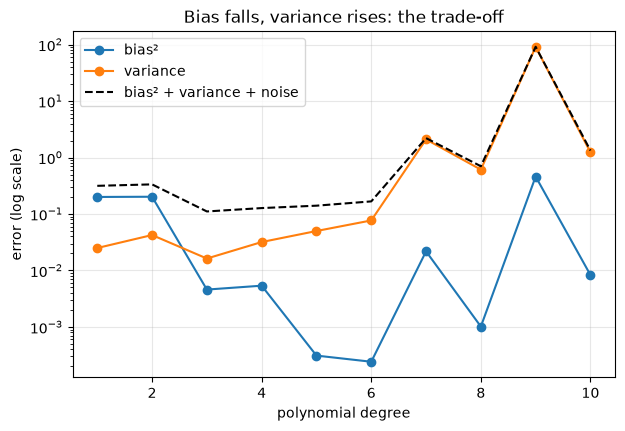

In [4]:
truth = true_fn(grid.ravel())
degs = list(range(1, 11))
bias2, var = [], []
for d in degs:
    preds = []
    for _ in range(200):
        xs = rng.uniform(0, 1, n_train)
        ys = true_fn(xs) + rng.normal(0, noise_sd, n_train)
        preds.append(poly_model(d).fit(xs.reshape(-1, 1), ys).predict(grid))
    preds = np.array(preds)
    bias2.append(np.mean((preds.mean(axis=0) - truth) ** 2))  # how far the AVERAGE model is from truth
    var.append(np.mean(preds.var(axis=0)))                   # how much models disagree

total = np.array(bias2) + np.array(var) + noise_sd ** 2
result = pd.DataFrame({"degree": degs, "bias^2": bias2, "variance": var, "total": total}).round(4)
print(result.to_string(index=False))

plt.figure(figsize=(7, 4.5))
plt.plot(degs, bias2, "o-", label="bias²")
plt.plot(degs, var, "o-", label="variance")
plt.plot(degs, total, "k--", label="bias² + variance + noise")
plt.yscale("log")
plt.xlabel("polynomial degree"); plt.ylabel("error (log scale)")
plt.title("Bias falls, variance rises: the trade-off")
plt.legend(); plt.grid(alpha=0.3)
plt.savefig("reports/bias_variance_tradeoff.png", dpi=150)
plt.show()

The Experiment

 features p  all features  PCA (5 components)
          5         1.359               1.359
         10         0.636               0.650
         25         0.439               0.391
         50         0.587               0.329
         75         1.265               0.307
         90         4.178               0.291
        100       766.293               0.296
        110         2.985               0.298
        150         0.953               0.284
        300         0.458               0.265


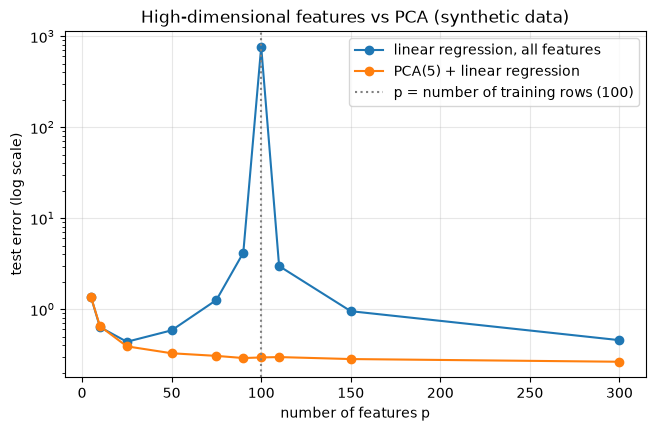

In [5]:
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def one_run(p, seed, n_train=100, n_test=1000):
    r = np.random.default_rng(seed)
    n = n_train + n_test
    z = r.normal(size=(n, 3))                       # 3 hidden factors
    W = r.normal(size=(3, p))
    X = z @ W + 0.5 * r.normal(size=(n, p))         # p observed features
    y = z @ np.array([2.0, -1.0, 1.5]) + 0.5 * r.normal(size=n)
    Xtr, Xte, ytr, yte = X[:n_train], X[n_train:], y[:n_train], y[n_train:]
    raw = make_pipeline(StandardScaler(), LinearRegression()).fit(Xtr, ytr)
    pca = make_pipeline(StandardScaler(), PCA(n_components=5),
                        LinearRegression()).fit(Xtr, ytr)
    return (mean_squared_error(yte, raw.predict(Xte)),
            mean_squared_error(yte, pca.predict(Xte)))

p_values = [5, 10, 25, 50, 75, 90, 100, 110, 150, 300]
rows = []
for p in p_values:
    res = np.array([one_run(p, seed) for seed in range(10)])
    rows.append({"features p": p,
                 "all features": res[:, 0].mean(),
                 "PCA (5 components)": res[:, 1].mean()})
hd = pd.DataFrame(rows)
print(hd.round(3).to_string(index=False))

plt.figure(figsize=(7.5, 4.5))
plt.plot(hd["features p"], hd["all features"], "o-", label="linear regression, all features")
plt.plot(hd["features p"], hd["PCA (5 components)"], "o-", label="PCA(5) + linear regression")
plt.axvline(100, color="gray", linestyle=":", label="p = number of training rows (100)")
plt.yscale("log")
plt.xlabel("number of features p"); plt.ylabel("test error (log scale)")
plt.title("High-dimensional features vs PCA (synthetic data)")
plt.legend(); plt.grid(alpha=0.3)
plt.savefig("reports/high_dim_pca.png", dpi=150)
plt.show()

In [7]:
YEARS = [2019, 2020, 2021, 2022, 2023, 2024, 2025]
data = {y: load_year(y) for y in YEARS}

table = share_table(data, top_n=12)
table   # rows = languages, columns = years, values = % of respondents

2019: already downloaded
2020: already downloaded
2021: already downloaded
2022: downloading... (may take a minute)
2022: saved to data\raw\survey_2022.csv
2023: already downloaded
2024: downloading... (may take a minute)
2024: saved to data\raw\survey_2024.csv
2025: already downloaded


,2019,2020,2021,2022,2023,2024,2025
JavaScript,67.63,69.83,65.07,65.44,63.93,62.75,66.32
HTML/CSS,63.34,65.66,56.17,55.15,53.24,53.25,62.20
SQL,54.29,57.62,47.15,49.49,48.91,51.35,58.83
Python,41.62,43.97,48.32,48.12,49.53,51.42,58.13
Bash/Shell (all shells),NaN,NaN,NaN,NaN,32.54,34.17,48.95
TypeScript,21.15,28.43,30.25,34.87,39.06,38.75,43.76
Java,41.02,37.45,35.41,33.31,30.71,30.53,29.55
C#,30.94,37.07,27.91,28.01,27.76,27.31,27.95
C++,23.44,20.92,24.35,22.58,22.53,23.14,23.63
PowerShell,NaN,NaN,10.77,12.08,13.66,13.94,23.27


Fit polynomial trends with leave-one-year-out testing

In [8]:
from sklearn.linear_model import LinearRegression

rows = []
for lang in table.index:
    s = table.loc[lang].dropna()
    if len(s) < 5:
        print("Skipping", lang, "- only", len(s), "years of data")
        continue
    x = (s.index.values - 2022).reshape(-1, 1)   # centre years around 2022
    y = s.values
    errs = {d: loo_mse(x, y, d) for d in (1, 2, 3)}
    best_deg = min((1, 2), key=lambda d: errs[d])    # forecast only with degree 1 or 2
    slope = LinearRegression().fit(x, y).coef_[0]    # percentage points per year
    rows.append({"skill": lang,
                 "share_latest_%": y[-1],
                 "slope_pp_per_year": slope,
                 "LOO_err_deg1": errs[1], "LOO_err_deg2": errs[2], "LOO_err_deg3": errs[3],
                 "best_degree(1or2)": best_deg})

trends = pd.DataFrame(rows).sort_values("slope_pp_per_year", ascending=False)
print(trends.round(2).to_string(index=False))

Skipping Bash/Shell (all shells) - only 3 years of data
     skill  share_latest_%  slope_pp_per_year  LOO_err_deg1  LOO_err_deg2  LOO_err_deg3  best_degree(1or2)
TypeScript           43.76               3.47          5.21          6.24          8.93                  1
PowerShell           23.27               2.69         20.22         28.88         61.18                  1
    Python           58.13               2.34          5.28         11.34         10.55                  1
         C           22.06               0.23          2.26          1.53          7.00                  2
       C++           23.63               0.11          1.89          2.60         11.65                  1
       SQL           58.83               0.10         39.08         32.32         52.99                  2
JavaScript           66.32              -0.69          6.77         13.09          7.66                  1
        C#           27.95              -1.02         12.96         27.75         85.00 

Plot trends and a careful 2-year outlook

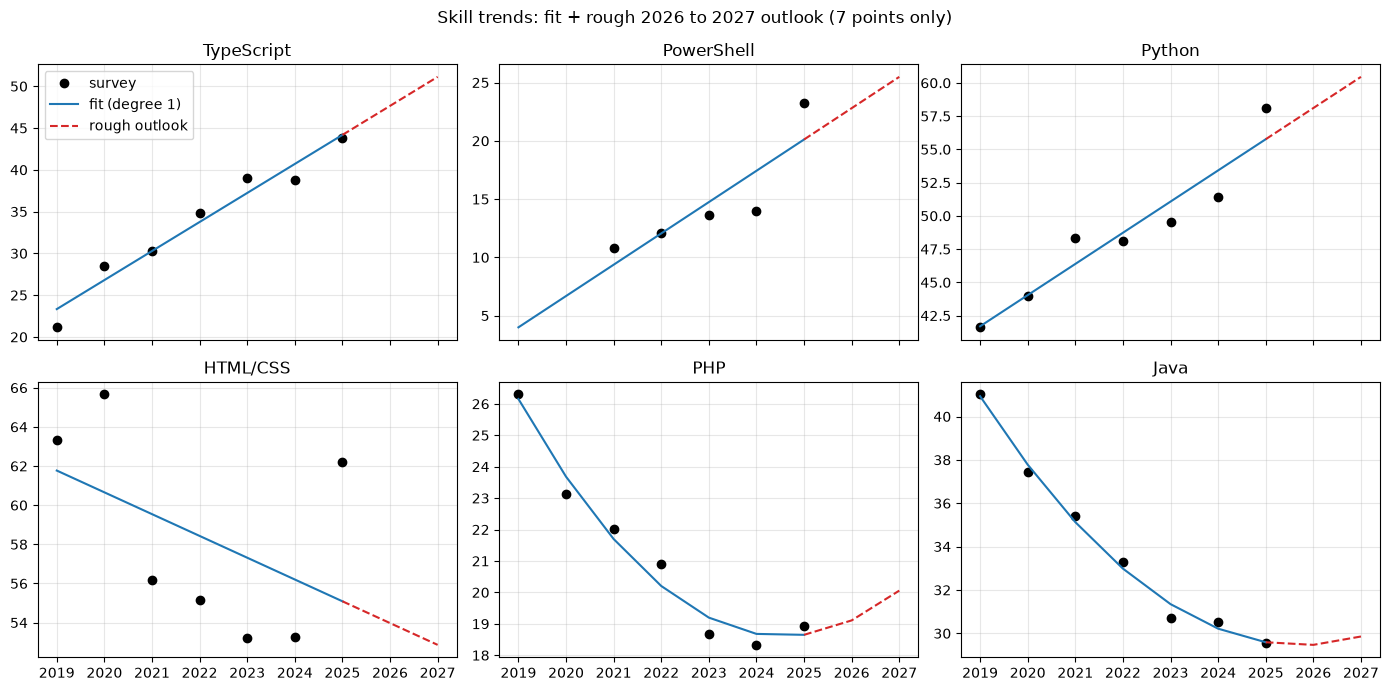

In [9]:
top_rising = trends.head(3)["skill"].tolist()
top_falling = trends.tail(3)["skill"].tolist()
chosen = top_rising + top_falling

fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True)
for ax, lang in zip(axes.ravel(), chosen):
    s = table.loc[lang].dropna()
    x = (s.index.values - 2022).reshape(-1, 1)
    deg = int(trends.loc[trends.skill == lang, "best_degree(1or2)"].iloc[0])
    m = poly_model(deg).fit(x, s.values)
    xs = np.arange(-3, 6).reshape(-1, 1)             # 2019 ... 2027
    pred = np.clip(m.predict(xs), 0, 100)
    ax.plot(s.index, s.values, "o", color="black", label="survey")
    ax.plot((xs.ravel() + 2022)[:7], pred[:7], color="tab:blue", label=f"fit (degree {deg})")
    ax.plot((xs.ravel() + 2022)[6:], pred[6:], "--", color="tab:red", label="rough outlook")
    ax.set_title(lang); ax.grid(alpha=0.3)
axes[0, 0].legend()
fig.suptitle("Skill trends: fit + rough 2026 to 2027 outlook (7 points only)")
plt.tight_layout()
plt.savefig("reports/skill_trend_outlook.png", dpi=150)
plt.show()

The “radar” ranking chart and a small summary file

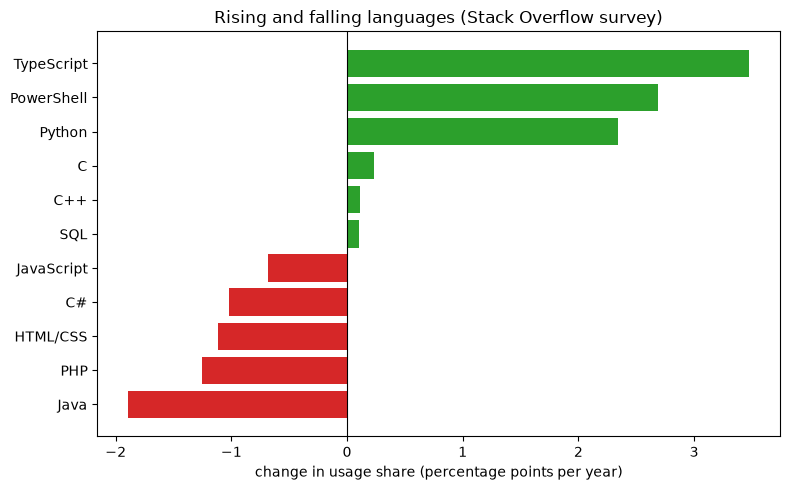

In [10]:
t = trends.sort_values("slope_pp_per_year")
colors = ["tab:green" if v > 0 else "tab:red" for v in t["slope_pp_per_year"]]
plt.figure(figsize=(8, 5))
plt.barh(t["skill"], t["slope_pp_per_year"], color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("change in usage share (percentage points per year)")
plt.title("Rising and falling languages (Stack Overflow survey)")
plt.tight_layout()
plt.savefig("reports/skill_radar_languages.png", dpi=150)
plt.show()

# Small aggregated summary (needed later by the Streamlit app)
trends.round(3).to_csv("reports/skill_trends_languages.csv", index=False)
table.to_csv("reports/language_share_by_year.csv")